In [1]:
from HINGE.evaluation_synthetic import run_synthetic_evaluation_with_dropout

from HINGE.feature_mapping import prepare_expression_features

from sklearn.preprocessing import normalize
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

In [2]:
SAVE_DIR = Path('./hinge_checkpoints')
SAVE_DIR.mkdir(exist_ok=True)

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
with open(SAVE_DIR / 'checkpoint_step1.pkl', "rb") as f:
    data_dict=pickle.load(f)

data_dict

{'RNA_panel1': {'s1': AnnData object with n_obs × n_vars = 6989 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's2': AnnData object with n_obs × n_vars = 8978 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's3': AnnData object with n_obs × n_vars = 449221 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's4': AnnData object with n_obs × n_vars = 7442 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's5': AnnData object with n_obs × n_vars = 16540 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'f

# run all samples(excluding sample 3)

In [5]:
sample_pairs = [
    ("s1", "s7", 0),
    ("s2", "s8", 1),
    ("s4", "s10", 3),
    ("s5", "s11", 4),
    ("s6", "s12", 5),
]

all_accuracy = []
all_celltypes = []
all_fakes = []

for p1_name, p2_name, idx in sample_pairs:

    print(f"Running {p1_name} -> {p2_name}")

    adata_panel1 = data_dict["RNA_panel1"][p1_name]
    adata_panel2 = data_dict["RNA_panel2"][p2_name]

    uni_panel1 = data_dict["HE_panel1"][idx].copy()
    uni_panel2 = data_dict["HE_panel2"][idx].copy()

    uni_panel1.X = normalize(uni_panel1.X)
    uni_panel2.X = normalize(uni_panel2.X)

    df_acc, df_ct, fakes, stats = run_synthetic_evaluation_with_dropout(
        adata_panel1=adata_panel1,
        uni_panel1_normed=uni_panel1,
        adata_panel2=adata_panel2,
        uni_panel2_normed=uni_panel2,

        alpha_list=[0.5,0.75,1.0,1.25,1.5,1.75],
        n_seeds_per_alpha=2,

        MAX_DIST=None,

        dropout_frac=0.10,
        dropout_mode="independent",

        SAMPLE_NAME=p1_name,

        N_PCA_MORPH=2048,
        n_gene_comps=512,

        evaluate_hinge=True,
        leiden_resolution=0.5,
        min_cells_per_cluster=20,

        evaluate_celltype=True,
        celltype_key="cell_type",

        run_hinge2=False,
        run_hinge3=False,
        run_hinge4=False,
        run_hinge5=True,
    )

    df_acc["sample"] = p1_name
    df_ct["sample"] = p1_name

    all_accuracy.append(df_acc)
    all_celltypes.append(df_ct)
    all_fakes.append(fakes)

accuracy_df = pd.concat(all_accuracy)
celltype_df = pd.concat(all_celltypes)

accuracy_df.to_csv("accuracy_all_samples.csv", index=False)
celltype_df.to_csv("celltype_all_samples.csv", index=False)

Running s1 -> s7
  Computing population-level difference statistics
  Panel1: 6989 cells  |  Panel2: 6881 cells

  Coordinate displacement field:
    median dx        = +0.64 um
    median dy        = +0.88 um
    median NN dist   = 20.76 um
    kept fraction    = 100.0%

  UNI (normalized space, 2048D):
    |delta_mean| median = 0.00258
    delta_std    median = 0.01700

  Expression (444 genes):
    |delta_mean| median = 0.0725
    delta_std    median = 0.1548
  Created s1_t: alpha=0.50  seed=0  xy_method=displacement_field  mean coord shift=20.41 um  n=6989
  Created s1_t: alpha=0.50  seed=1  xy_method=displacement_field  mean coord shift=20.46 um  n=6989
  Created s1_t: alpha=0.75  seed=2  xy_method=displacement_field  mean coord shift=29.17 um  n=6989
  Created s1_t: alpha=0.75  seed=3  xy_method=displacement_field  mean coord shift=29.30 um  n=6989
  Created s1_t: alpha=1.00  seed=4  xy_method=displacement_field  mean coord shift=38.63 um  n=6989
  Created s1_t: alpha=1.00  seed=

/home/yyamamo2/.conda/envs/cosie_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



  Joint UNI clustering  (resolution=1.0)
    Input cells    : P1=6290  P2=6290  total=12580
    Raw clusters   : 29
    After merging  : 29
    Cluster sizes  : min=57, median=417, max=1360

  Cross-panel cluster fractions  (joint clustering)
   Cluster    P1 frac    P2 frac        Δ
         0      0.035      0.034    0.001
         1      0.032      0.034    0.002
         2      0.035      0.036    0.001
         3      0.021      0.021    0.000
         4      0.010      0.010    0.001
         5      0.010      0.011    0.000
         6      0.038      0.038    0.000
         7      0.016      0.016    0.000
         8      0.049      0.048    0.001
         9      0.048      0.046    0.002
        10      0.013      0.013    0.000
        11      0.064      0.065    0.002
        12      0.059      0.060    0.001
        13      0.047      0.045    0.002
        14      0.062      0.062    0.000
        15      0.021      0.022    0.001
        16      0.056      0.054    0.002


In [6]:
plot_dir = Path("./presentation_plots")
os.makedirs(plot_dir, exist_ok=True)

# plot 1 Distance -only accuracy

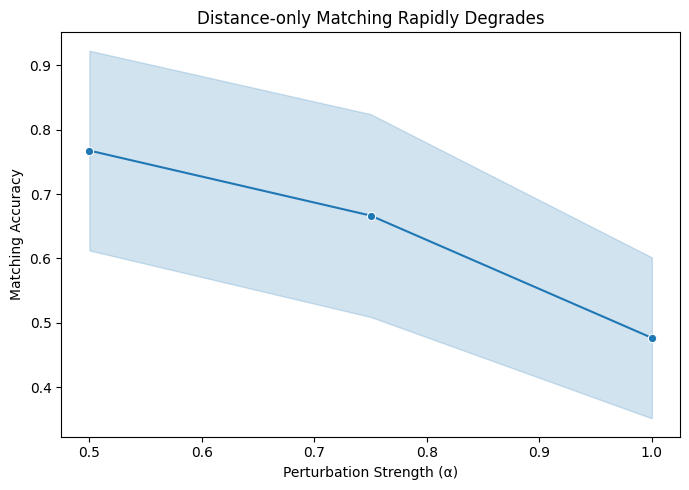

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

dist_df = accuracy_df[
    (accuracy_df["strategy"] == "A_distance") &
    (accuracy_df["alpha"] <= 1.0)
]

plt.figure(figsize=(7,5))

sns.lineplot(
    data=dist_df,
    x="alpha",
    y="accuracy_eval",
    errorbar="sd",
    marker="o"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Distance-only Matching Rapidly Degrades")
plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig1_distance_only_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

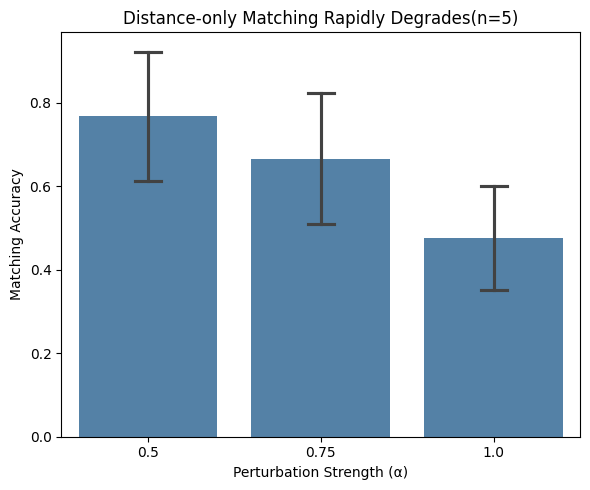

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

alphas_to_plot = [0.5, 0.75, 1.0]

dist_df = accuracy_df[
    (accuracy_df["strategy"] == "A_distance") &
    (accuracy_df["alpha"].isin(alphas_to_plot))
]

plt.figure(figsize=(6,5))

sns.barplot(
    data=dist_df,
    x="alpha",
    y="accuracy_eval",
    errorbar="sd",
    capsize=0.15,
    color="steelblue"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Distance-only Matching Rapidly Degrades(n=5)")

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig1_distance_only_accuracy_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

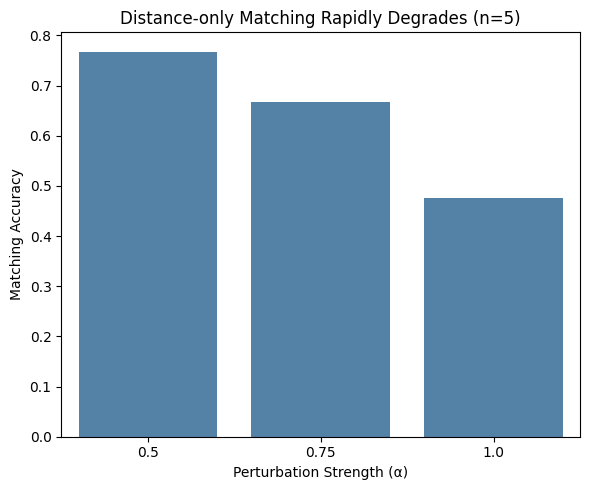

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

alphas_to_plot = [0.5, 0.75, 1.0]

dist_df = accuracy_df[
    (accuracy_df["strategy"] == "A_distance") &
    (accuracy_df["alpha"].isin(alphas_to_plot))
]

plt.figure(figsize=(6,5))

sns.barplot(
    data=dist_df,
    x="alpha",
    y="accuracy_eval",
    errorbar=None,
    color="steelblue"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Distance-only Matching Rapidly Degrades (n=5)")

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig1_distance_only_accuracy_bar_noerror.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot 2 Real vs Synthetic

In [31]:

uni_480_normalized_list = []

for adata in uni_480_list:
    adata_norm = adata.copy()
    adata_norm.X = normalize(adata.X)
    uni_480_normalized_list.append(adata_norm)


uni_5k_normalized_list = []

for adata in uni_5k_list:
    adata_norm = adata.copy()
    adata_norm.X = normalize(adata.X)
    uni_5k_normalized_list.append(adata_norm)


#select which sample to use for the mapping

uni_480_list = [data_dict['HE_panel1'][0]]  # only the first sample for demonstration
uni_5k_list = [data_dict['HE_panel2'][0]]  # only the first sample for demonstration
rna_480_list = [data_dict['RNA_panel1']['s1']]  # only the first sample for demonstration
rna_5k_list = [data_dict['RNA_panel2']['s7']]  # only the first sample for demonstration

adata_panel1          = rna_480_list[0]
uni_panel1_normed     = uni_480_normalized_list[0]
adata_panel2          = rna_5k_list[0]
uni_panel2_normed     = uni_5k_normalized_list[0]


overlap_genes = list(set(adata_panel1.var_names) & set(adata_panel2.var_names))

In [42]:
from HINGE.synthetic_data_whole import create_synthetic_replicates
from HINGE.utils import compute_population_diff_stats
import matplotlib.pyplot as plt
from HINGE.utils import _xy
import numpy as np




stats = compute_population_diff_stats(
        adata_panel1   = adata_panel1,
        uni_panel1_normed     = uni_panel1_normed,
        adata_panel2   = adata_panel2,
        uni_panel2_normed     = uni_panel2_normed,
        overlap_genes  = overlap_genes,
        spatial_key_p1 =  "spatial",
        spatial_key_p2 = "spatial_registered",
    )

    # Step 2: replicates
fakes = create_synthetic_replicates(
        adata_panel1      = adata_panel1,
        uni_panel1_normed = uni_panel1_normed,
        stats             = stats,
        alpha_list        = [0.25, 0.5,0.75,1, 1.25, 1.5, 1.75],
        n_seeds_per_alpha = 1,
        noise_scale       = 1.0,
        spatial_key       =  "spatial",
        RECENTER          = False,
        xy_method="displacement_field",
        xy_k=20,
        xy_local_noise_weight=0.25,
)


  Computing population-level difference statistics
  Panel1: 6989 cells  |  Panel2: 6881 cells

  Coordinate displacement field:
    median dx        = +0.64 um
    median dy        = +0.88 um
    median NN dist   = 20.76 um
    kept fraction    = 100.0%

  UNI (normalized space, 2048D):
    |delta_mean| median = 0.00258
    delta_std    median = 0.01700

  Expression (444 genes):
    |delta_mean| median = 0.0725
    delta_std    median = 0.1548
  Created s1_t: alpha=0.25  seed=0  xy_method=displacement_field  mean coord shift=12.18 um  n=6989
  Created s1_t: alpha=0.50  seed=1  xy_method=displacement_field  mean coord shift=20.46 um  n=6989
  Created s1_t: alpha=0.75  seed=2  xy_method=displacement_field  mean coord shift=29.17 um  n=6989
  Created s1_t: alpha=1.00  seed=3  xy_method=displacement_field  mean coord shift=38.48 um  n=6989
  Created s1_t: alpha=1.25  seed=4  xy_method=displacement_field  mean coord shift=47.91 um  n=6989
  Created s1_t: alpha=1.50  seed=5  xy_method=disp

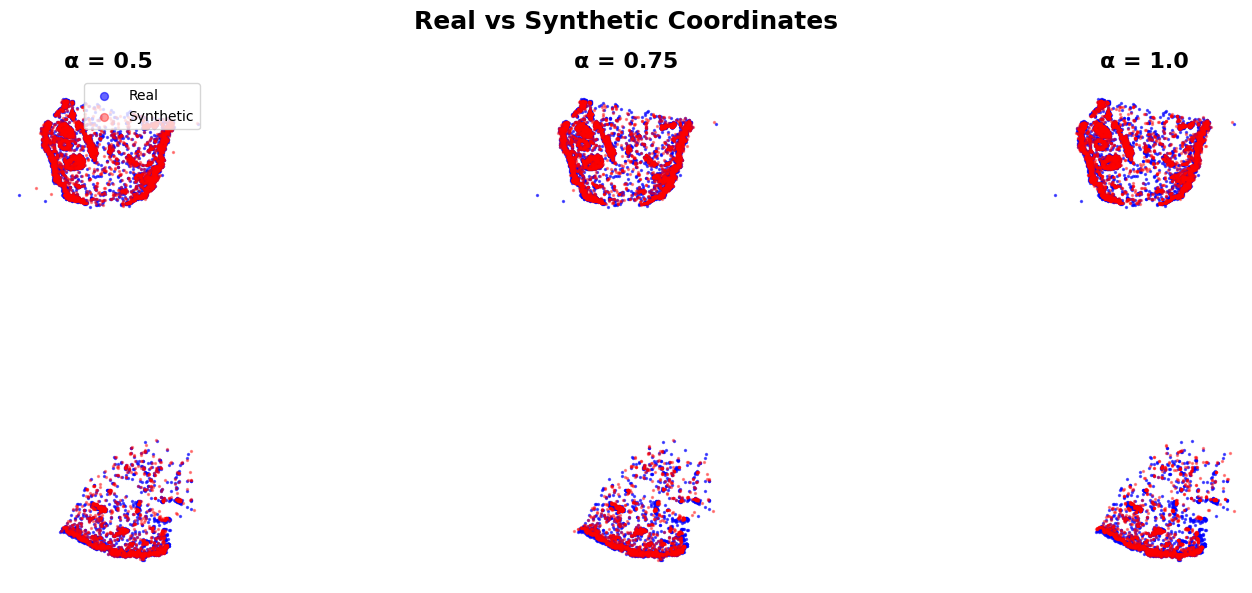

In [50]:
from HINGE.utils import _xy
import matplotlib.pyplot as plt
import numpy as np

def plot_real_vs_fake_overlays(
    adata_panel1,
    fakes,
    spatial_key="spatial",
    alpha_list=[0.5, 0.75, 1.0],
    n_sample=5000,
    point_size=2,
    save_path=None
):

    xy_real = _xy(adata_panel1, spatial_key)

    rng = np.random.default_rng(42)

    idx_real = rng.choice(
        len(xy_real),
        min(n_sample, len(xy_real)),
        replace=False
    )

    fig, axes = plt.subplots(
        1,
        len(alpha_list),
        figsize=(18,6),
        sharex=True,
        sharey=True
    )

    if len(alpha_list) == 1:
        axes = [axes]

    for ax, alpha in zip(axes, alpha_list):

        # find fake corresponding to this alpha
        fake = next(
            f for f in fakes
            if np.isclose(f["alpha"], alpha)
        )

        xy_fake = fake["xy"]

        idx_fake = rng.choice(
            len(xy_fake),
            min(n_sample, len(xy_fake)),
            replace=False
        )

        # real
        ax.scatter(
            xy_real[idx_real,0],
            xy_real[idx_real,1],
            s=point_size,
            color="blue",
            alpha=0.6,
            label="Real"
        )

        # fake
        ax.scatter(
            xy_fake[idx_fake,0],
            xy_fake[idx_fake,1],
            s=point_size,
            color="red",
            alpha=0.4,
            label="Synthetic"
        )

        ax.set_title(
            f"α = {alpha}",
            fontsize=16,
            fontweight="bold"
        )

        ax.axis("off")
        ax.set_aspect("equal")

    axes[0].legend(
        loc="upper right",
        markerscale=4
    )

    plt.suptitle(
        "Real vs Synthetic Coordinates",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout()

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()



plot_real_vs_fake_overlays(
    adata_panel1=adata_panel1,
    fakes=fakes,
    alpha_list=[0.5, 0.75, 1.0],
    n_sample=5000,
    save_path=f"{plot_dir}/Fig2_spatial_overlay.png"
)

# Plot 3  Distance vs Expression

/tmp/ipykernel_1311705/418496541.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["method"] = plot_df["strategy"].map(rename)


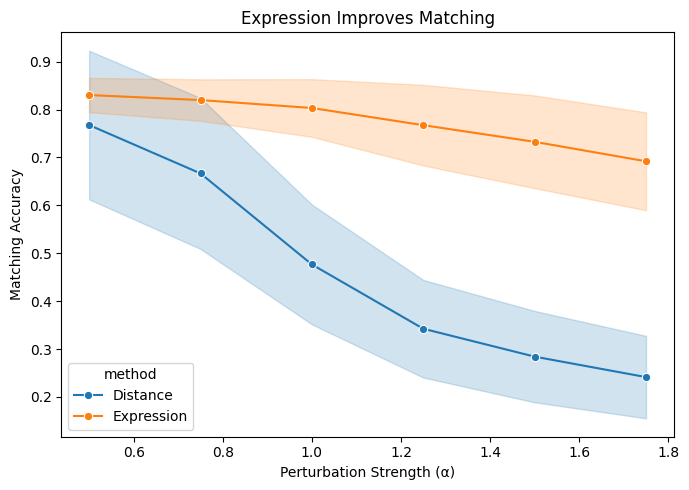

In [52]:
plot_df = accuracy_df[
    accuracy_df["strategy"].isin([
        "A_distance",
        "C_expression",
    ])
]

rename = {
    "A_distance":"Distance",
    "C_expression":"Expression"
}

plot_df["method"] = plot_df["strategy"].map(rename)

plt.figure(figsize=(7,5))

sns.lineplot(
    data=plot_df,
    x="alpha",
    y="accuracy_eval",
    hue="method",
    marker="o",
    errorbar="sd"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Expression Improves Matching")
plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig3_expression_vs_distance.png",
    dpi=300
)

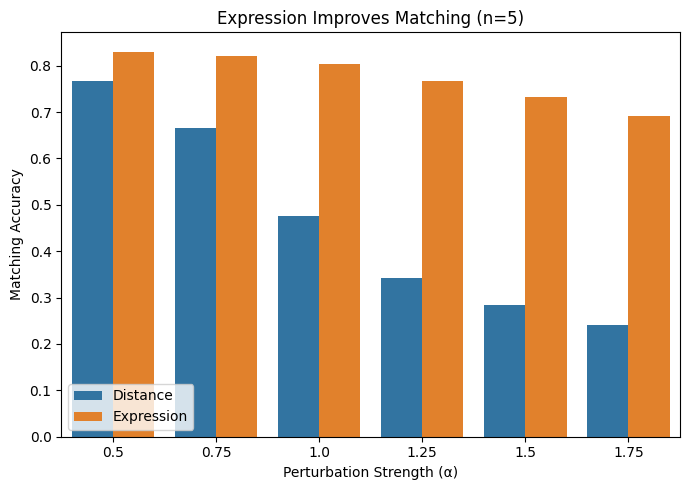

In [55]:
plot_df = accuracy_df[
    accuracy_df["strategy"].isin([
        "A_distance",
        "C_expression",
    ])
].copy()

rename = {
    "A_distance": "Distance",
    "C_expression": "Expression"
}

plot_df["method"] = plot_df["strategy"].map(rename)

plt.figure(figsize=(7,5))

sns.barplot(
    data=plot_df,
    x="alpha",
    y="accuracy_eval",
    hue="method",
    errorbar=None
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Expression Improves Matching (n=5)")

plt.legend(
    loc="lower left",
    frameon=True
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig3_expression_vs_distance_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

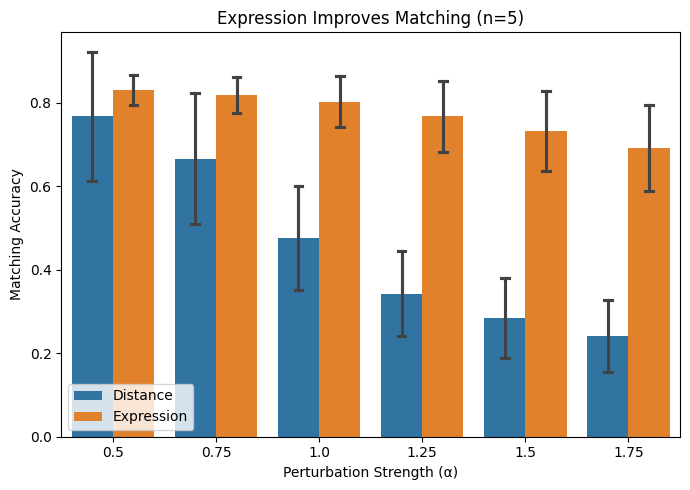

In [56]:
plot_df = accuracy_df[
    accuracy_df["strategy"].isin([
        "A_distance",
        "C_expression",
    ])
].copy()

rename = {
    "A_distance": "Distance",
    "C_expression": "Expression"
}

plot_df["method"] = plot_df["strategy"].map(rename)

plt.figure(figsize=(7,5))

sns.barplot(
    data=plot_df,
    x="alpha",
    y="accuracy_eval",
    hue="method",
    errorbar="sd",   # <- standard deviation
    capsize=0.15
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Expression Improves Matching (n=5)")

plt.legend(
    loc="lower left",
    frameon=True
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig3_expression_vs_distance_bar_sd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot 4 HINGE figure

/tmp/ipykernel_1311705/1525941576.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["method"] = plot_df["strategy"].map(rename)


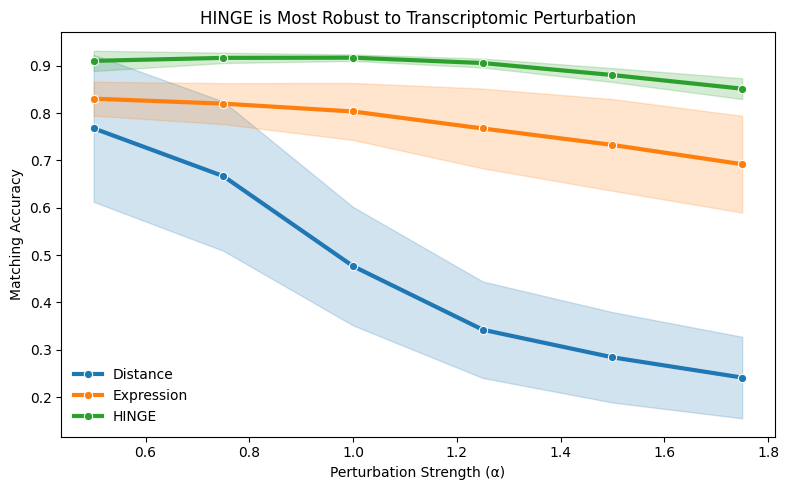

In [57]:
plot_df = accuracy_df[
    accuracy_df["strategy"].isin([
        "A_distance",
        "C_expression",
        "I_HINGE5"
    ])
]

rename = {
    "A_distance":"Distance",
    "C_expression":"Expression",
    "I_HINGE5":"HINGE"
}

plot_df["method"] = plot_df["strategy"].map(rename)

plt.figure(figsize=(8,5))

sns.lineplot(
    data=plot_df,
    x="alpha",
    y="accuracy_eval",
    hue="method",
    marker="o",
    linewidth=3,
    errorbar="sd"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("HINGE is Most Robust to Transcriptomic Perturbation")

plt.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig4_hinge_main_result.png",
    dpi=300,
    bbox_inches="tight"
)


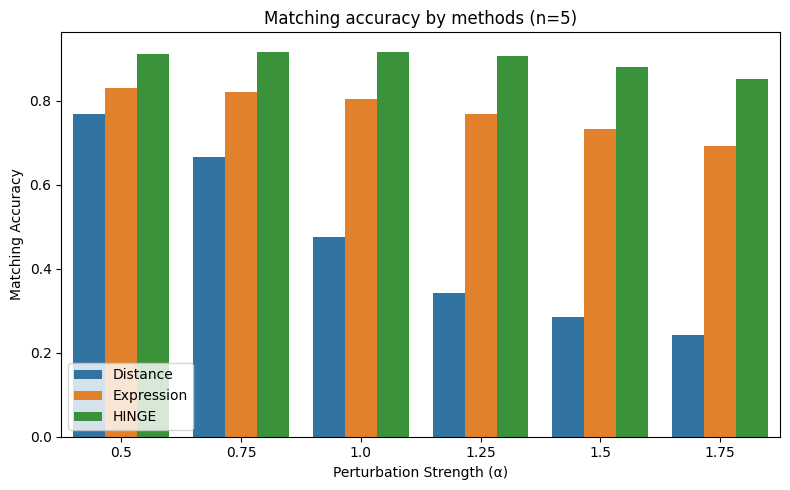

In [90]:
errorbar=None


plot_df = accuracy_df[
    accuracy_df["strategy"].isin([
        "A_distance",
        "C_expression",
        "I_HINGE5"
    ])
].copy()

rename = {
    "A_distance": "Distance",
    "C_expression": "Expression",
    "I_HINGE5": "HINGE"
}

plot_df["method"] = plot_df["strategy"].map(rename)

plt.figure(figsize=(8,5))

sns.barplot(
    data=plot_df,
    x="alpha",
    y="accuracy_eval",
    hue="method",
    errorbar=None
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Matching accuracy by methods (n=5)")

plt.legend(
    loc="lower left",
    frameon=True
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig4_hinge_main_result_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot 5 Rare Cell Types

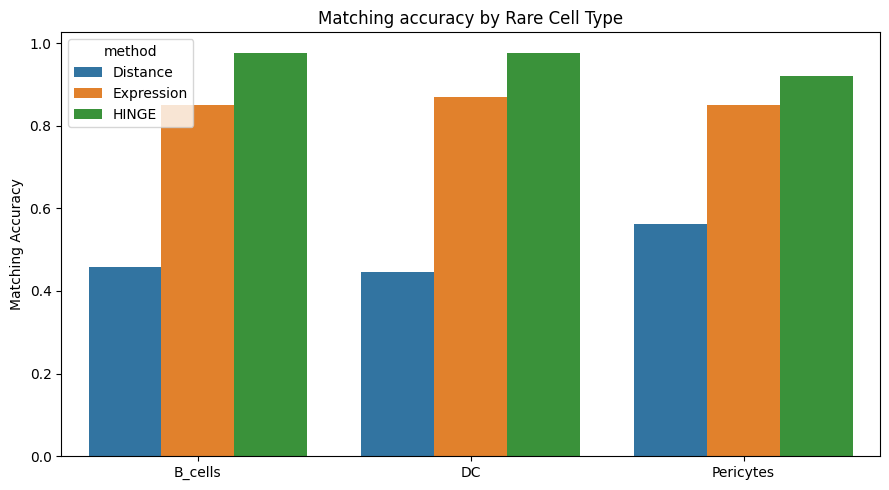

In [89]:
rare_types = [
    "B_cells",
    "DC",
    "Pericytes"
]

plot_df = celltype_df[
    celltype_df["cell_type"].isin(rare_types)
]

plot_df = plot_df[
    plot_df["strategy"].isin([
        "A_distance",
        "C_expression",
        "I_HINGE5"
    ])
]

rename = {
    "A_distance":"Distance",
    "C_expression":"Expression",
    "I_HINGE5":"HINGE"
}

plot_df["method"] = plot_df["strategy"].map(rename)

summary = (
    plot_df
    .groupby(
        ["cell_type","method"]
    )["matching_accuracy"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=summary,
    x="cell_type",
    y="matching_accuracy",
    hue="method"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("")
plt.title("Matching accuracy by Rare Cell Type")

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig5_rare_celltypes.png",
    dpi=300
)


# Plot 6 Gain over Distance

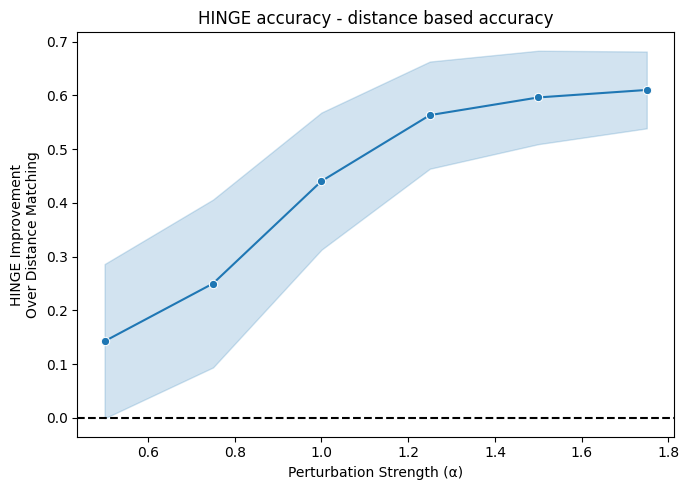

In [76]:
pivot = accuracy_df.pivot_table(
    index=["sample","alpha"],
    columns="strategy",
    values="accuracy_eval"
)

gain = (
    pivot["I_HINGE5"]
    - pivot["A_distance"]
)

gain = gain.reset_index()
gain.columns = ["sample","alpha","gain"]

plt.figure(figsize=(7,5))

sns.lineplot(
    data=gain,
    x="alpha",
    y="gain",
    marker="o",
    errorbar="sd"
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.ylabel(
    "HINGE Improvement\nOver Distance Matching"
)

plt.xlabel("Perturbation Strength (α)")

plt.title(
    "HINGE accuracy - distance based accuracy"
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig6_hinge_gain_vs_distance.png",
    dpi=300
)

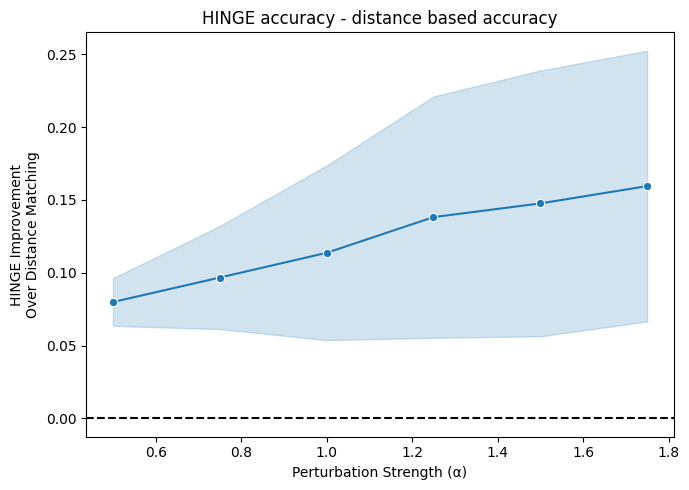

In [78]:
pivot = accuracy_df.pivot_table(
    index=["sample","alpha"],
    columns="strategy",
    values="accuracy_eval"
)

gain = (
    pivot["I_HINGE5"]
    - pivot["C_expression"]
)

gain = gain.reset_index()
gain.columns = ["sample","alpha","gain"]

plt.figure(figsize=(7,5))

sns.lineplot(
    data=gain,
    x="alpha",
    y="gain",
    marker="o",
    errorbar="sd"
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.ylabel(
    "HINGE Improvement\nOver Distance Matching"
)

plt.xlabel("Perturbation Strength (α)")

plt.title(
    "HINGE accuracy - distance based accuracy"
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig6_hinge_gain_vs_gene_expression.png",
    dpi=300
)

# No Dropout plots


In [81]:
from sklearn.preprocessing import normalize
import pandas as pd
from HINGE.evaluation_synthetic import run_synthetic_evaluation
from HINGE.utils import get_overlapping_genes

sample_pairs = [
    ("s1", "s7", 0),
    ("s2", "s8", 1),
    ("s4", "s10", 3),
    ("s5", "s11", 4),
    ("s6", "s12", 5),
]

all_results = []

for p1_name, p2_name, idx in sample_pairs:

    print(f"\nRunning {p1_name} vs {p2_name}")

    adata_panel1 = data_dict["RNA_panel1"][p1_name]
    adata_panel2 = data_dict["RNA_panel2"][p2_name]

    uni_panel1 = data_dict["HE_panel1"][idx].copy()
    uni_panel2 = data_dict["HE_panel2"][idx].copy()

    uni_panel1.X = normalize(uni_panel1.X)
    uni_panel2.X = normalize(uni_panel2.X)

    overlap_genes = get_overlapping_genes(
        [adata_panel1],
        [adata_panel2]
    )


    
    expr_p1, expr_p2, _, overlap_genes = (
        prepare_expression_features(
            [adata_panel1],
            [adata_panel2],
            n_comps=512
        )
    )

    df_acc, fakes, stats = run_synthetic_evaluation(

        adata_panel1      = adata_panel1,
        uni_panel1_normed = uni_panel1,

        adata_panel2      = adata_panel2,
        uni_panel2_normed = uni_panel2,

        expr_panel1       = expr_p1[0],
        overlap_genes     = overlap_genes,

        SAMPLE_NAME       = p1_name,

        alpha_list=[0.25, 0.5,0.75,1, 1.25, 1.5, 1.75],

        n_seeds_per_alpha=2,

        N_PCA_MORPH=2048,
        n_gene_comps=512,

        MAX_DIST=None,

        run_hinge=False,
    )

    df_acc["sample"] = p1_name

    all_results.append(df_acc)

df_no_dropout = pd.concat(all_results)

df_no_dropout.to_csv(
    "synthetic_no_dropout_all_samples.csv",
    index=False
)


Running s1 vs s7
  Computing population-level difference statistics
  Panel1: 6989 cells  |  Panel2: 6881 cells

  Coordinate displacement field:
    median dx        = +0.64 um
    median dy        = +0.88 um
    median NN dist   = 20.76 um
    kept fraction    = 100.0%

  UNI (normalized space, 2048D):
    |delta_mean| median = 0.00258
    delta_std    median = 0.01700

  Expression (444 genes):
    |delta_mean| median = 0.0725
    delta_std    median = 0.1548
  Created s1_t: alpha=0.25  seed=0  xy_method=displacement_field  mean coord shift=12.18 um  n=6989
  Created s1_t: alpha=0.25  seed=1  xy_method=displacement_field  mean coord shift=12.25 um  n=6989
  Created s1_t: alpha=0.50  seed=2  xy_method=displacement_field  mean coord shift=20.22 um  n=6989
  Created s1_t: alpha=0.50  seed=3  xy_method=displacement_field  mean coord shift=20.36 um  n=6989
  Created s1_t: alpha=0.75  seed=4  xy_method=displacement_field  mean coord shift=29.45 um  n=6989
  Created s1_t: alpha=0.75  seed

Text(0.5, 1.0, 'presentation_plots/Fig1B_Distance-only_Matching_Fails_Even_Without_Cell_Dropout')

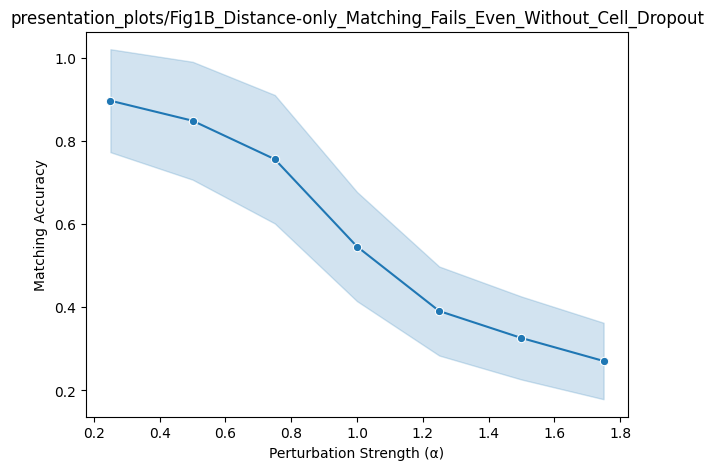

In [82]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = df_no_dropout[
    df_no_dropout["strategy"]=="A_distance"
]

plt.figure(figsize=(7,5))

sns.lineplot(
    data=plot_df,
    x="alpha",
    y="accuracy",
    marker="o",
    errorbar="sd",
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")

plt.title(
    f"{plot_dir}/Fig1B_Distance-only_Matching_Fails_Even_Without_Cell_Dropout"
)

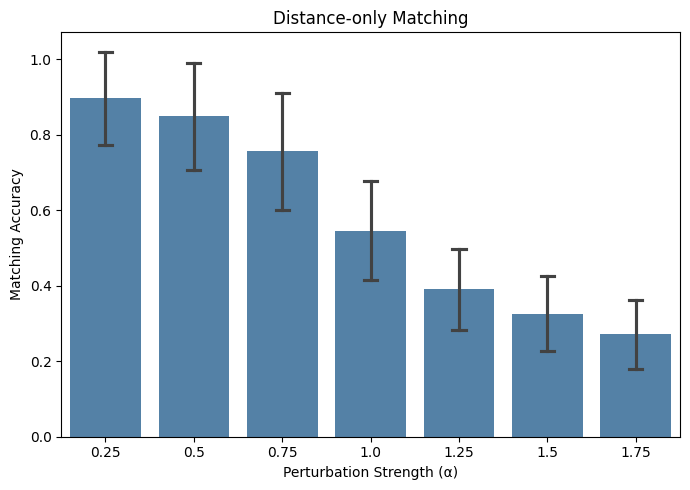

In [84]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = df_no_dropout[
    df_no_dropout["strategy"] == "A_distance"
]

plt.figure(figsize=(7,5))

sns.barplot(
    data=plot_df,
    x="alpha",
    y="accuracy",
    errorbar="sd",
    capsize=0.15,
    color="steelblue"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Distance-only Matching")

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig1B_Distance_only_Matching_Fails_Even_Without_Cell_Dropout.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

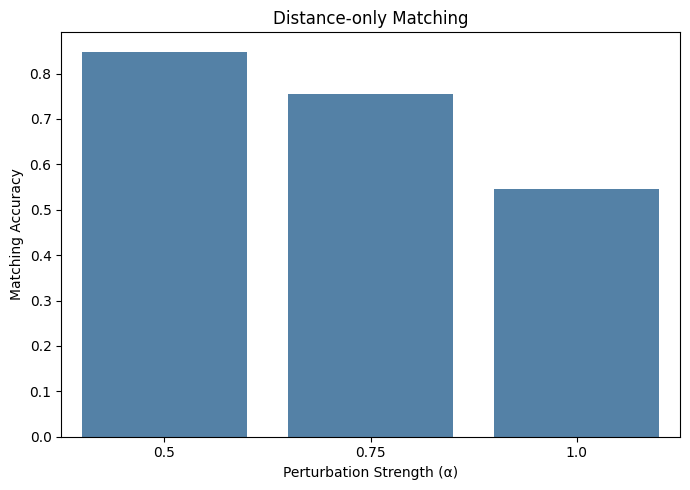

In [88]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = df_no_dropout[
    (df_no_dropout["strategy"] == "A_distance") &
    (df_no_dropout["alpha"].isin([0.5, 0.75, 1.0]))
]

plt.figure(figsize=(7,5))

sns.barplot(
    data=plot_df,
    x="alpha",
    y="accuracy",
    errorbar=None,   # remove if you want SD bars
    color="steelblue"
)

plt.ylabel("Matching Accuracy")
plt.xlabel("Perturbation Strength (α)")
plt.title("Distance-only Matching")

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/Fig1B_Distance_only_Matching_Fails_Even_Without_Cell_Dropout.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()